# Geração de Imagens e Treinamento Ângulo-Ordem (Order-CWT) nas 4 Arquiteturas

**Projeto:** Diagnóstico de Falhas em Rolamentos Industriais via CWT + Deep Learning  
**Metodologia:** Computed Order Tracking (COT) + Continuous Wavelet Transform (Order-CWT)  
**Arquiteturas Avaliadas:** **BearingCNN (Rede Autoral Leve)**, **ResNet-18**, **EfficientNet-B0** e **Inception-v3**  
**Objetivo:** Gerar escalogramas no domínio de ordens ($N_{\text{rev}} = 1.024$ amostras uniformes por volta do eixo, janela de 4 voltas, $0{,}5$ a $20{,}0$ ordens) para os três bancos de dados (**CWRU**, **Paderborn** e **XJTU-SY**) e treinar sistematicamente todas as **quatro arquiteturas convolucionais** sob invariância cinemática à rotação (RPM).

---

## 1. Importação de Módulos e Configurações

In [1]:
import sys
import json
from pathlib import Path

BASE_DIR = Path.cwd().parent.parent if Path.cwd().name in ['1_cwru', '2_paderborn', '3_xjtu', '4_cross_domain_tempo', '5_order_tracking', '6_confronto_final'] else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import torch
import numpy as np
import pandas as pd
from IPython.display import display
from src.config import (
    ORDER_CWRU_DIR,
    ORDER_PADERBORN_DIR,
    ORDER_XJTU_DIR,
    NUM_EPOCHS,
    LEARNING_RATE,
    RANDOM_SEED,
    set_seed
)
from src.generate_order_dataset import generate_all_order_datasets
from src.cnn_processor import train_and_evaluate_bearing_cnn
from src.transfer_learning import train_and_evaluate_transfer_model
from src.visualization import plot_training_curves, plot_confusion_matrix

set_seed(RANDOM_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[INFO] Dispositivo de treinamento: {device} | Semente Fixa: {RANDOM_SEED}')

resultados_order = {
    'CWRU': {},
    'Paderborn': {},
    'XJTU-SY': {}
}

[INFO] Dispositivo de treinamento: cuda | Semente Fixa: 42


## 2. Geração Automática dos Escalogramas Ângulo-Ordem (Order-CWT)

Gera os datasets em `data/order_tracking/cwru/`, `data/order_tracking/paderborn/` e `data/order_tracking/xjtu/` com particionamento estrito sem vazamento de dados (*Data Leakage*), remoção de offset DC por janela e normalização local por percentil (1 a 99%), garantindo total paridade metodológica com a CWT temporal. Caso os diretórios já estejam gerados em disco, a etapa é reutilizada automaticamente.

In [2]:
FORCE_REGENERATE = False

if (
    FORCE_REGENERATE
    or not (ORDER_CWRU_DIR / "train").exists()
    or not (ORDER_PADERBORN_DIR / "train").exists()
    or not (ORDER_XJTU_DIR / "train").exists()
):
    generate_all_order_datasets(max_files_per_class=10)
else:
    print("[INFO] Escalogramas Order-CWT já encontrados em disco para CWRU, Paderborn e XJTU-SY.")
    print("       Altere FORCE_REGENERATE = True caso deseje regerar as imagens do zero.")

[INFO] Escalogramas Order-CWT já encontrados em disco para CWRU, Paderborn e XJTU-SY.
       Altere FORCE_REGENERATE = True caso deseje regerar as imagens do zero.


## 3. Treinamento das 4 Arquiteturas no Dataset CWRU Ângulo-Ordem (`ORDER_CWRU_DIR`)

Treinamos a rede autoral `BearingCNN` (do zero) e os três modelos pré-treinados no ImageNet (`ResNet-18`, `EfficientNet-B0` e `Inception-v3`) via *Fine-Tuning* sobre os escalogramas Order-CWT do conjunto CWRU (4 classes).

### 3.1. CWRU Order-CWT: `BearingCNN` (Rede Autoral)

[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.8962 - Acc: 74.03% | Val Loss: 0.5079 - Acc: 86.42% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.3529 - Acc: 96.05% | Val Loss: 0.1644 - Acc: 99.00% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.1191 - Acc: 99.69% | Val Loss: 0.0707 - Acc: 99.95% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.0537 - Acc: 99.83% | Val Loss: 0.0576 - Acc: 99.06% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0310 - Acc: 99.92% | Val Loss: 0.0268 - Acc: 99.84% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.0178 - Acc: 99.97% | Val Loss: 0.0205 - Acc: 99.84% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0123 - Acc: 99.94% | Val Loss: 0.0188 - Acc: 99.69% [CHECKPOINT] Modelo ótimo salvo na época 07/10.
Época [08/10] | Tre

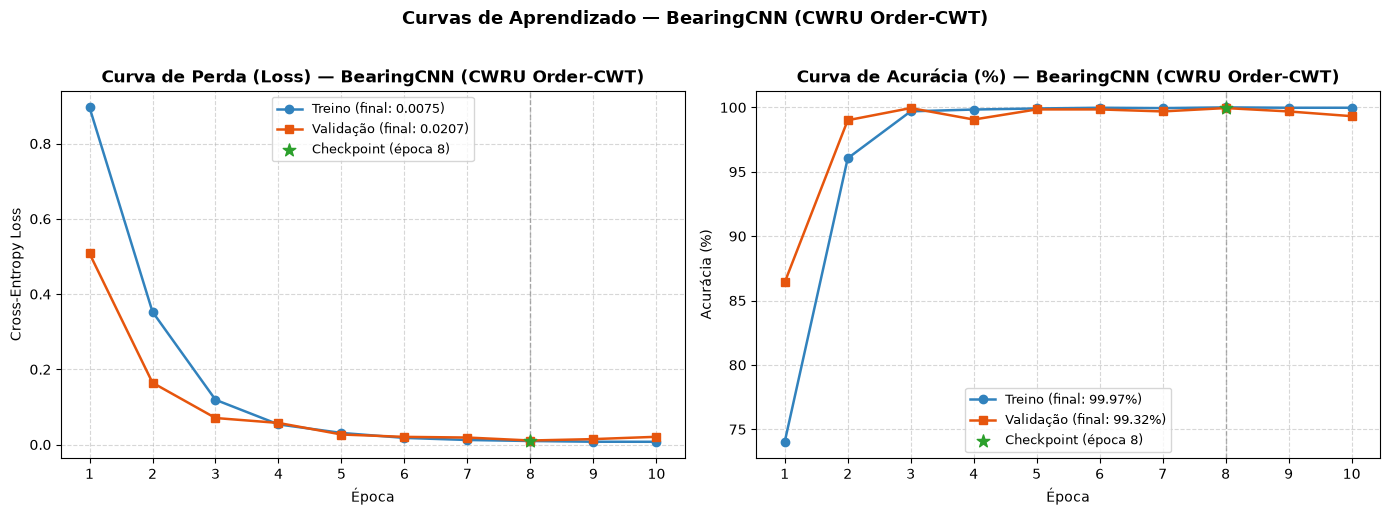

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_cwru_bearing_cnn.png


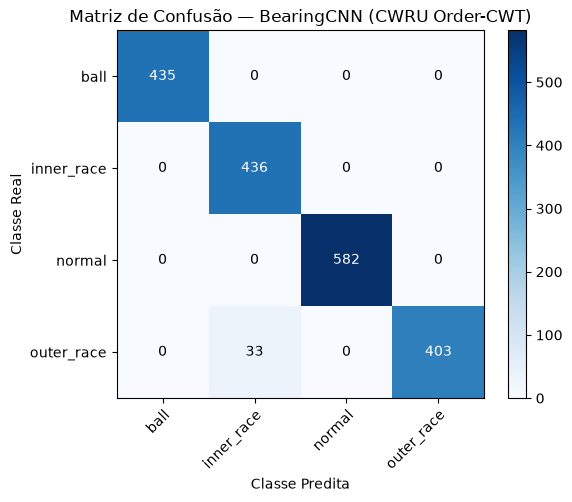

In [3]:
res_cwru_bcnn = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_CWRU_DIR,
    checkpoint_name="checkpoint_order_cwru_bearing_cnn_best.pth"
)
resultados_order["CWRU"]["BearingCNN"] = res_cwru_bcnn

plot_training_curves(
    res_cwru_bcnn["history"],
    model_name="BearingCNN (CWRU Order-CWT)",
    save_path="../../docs/images/training_curves_order_cwru_bearing_cnn.png"
)

plot_confusion_matrix(
    res_cwru_bcnn,
    model_name="BearingCNN (CWRU Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_cwru_bearing_cnn.png"
)

### 3.2. CWRU Order-CWT: `ResNet-18` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: RESNET18 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.1224 - Acc: 96.24% | Val Loss: 0.0040 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.0046 - Acc: 100.00% | Val Loss: 0.0010 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.0021 - Acc: 100.00% | Val Loss: 0.0006 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.0013 - Acc: 100.00% | Val Loss: 0.0005 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0013 - Acc: 100.00% | Val Loss: 0.0004 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.0008 - Acc: 100.00% | Val Loss: 0.0003 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0005 - Acc: 100.00% | Val Loss: 0.0003 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo n

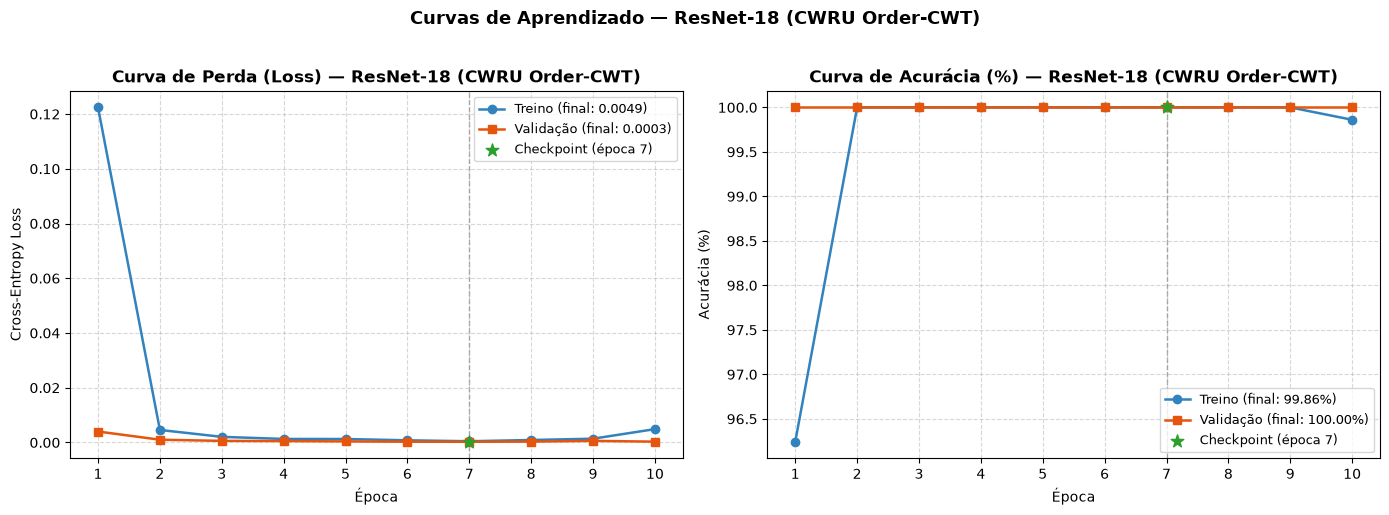

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_cwru_resnet.png


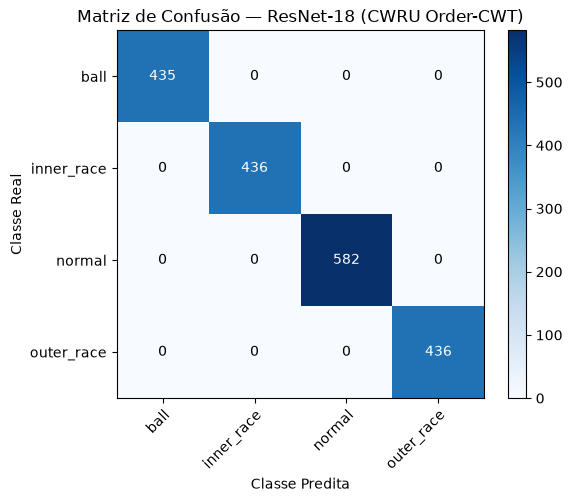

In [4]:
res_cwru_resnet = train_and_evaluate_transfer_model(
    model_name="resnet18",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_CWRU_DIR,
    checkpoint_prefix="checkpoint_order_cwru"
)
resultados_order["CWRU"]["ResNet-18"] = res_cwru_resnet

plot_training_curves(
    res_cwru_resnet["history"],
    model_name="ResNet-18 (CWRU Order-CWT)",
    save_path="../../docs/images/training_curves_order_cwru_resnet.png"
)

plot_confusion_matrix(
    res_cwru_resnet,
    model_name="ResNet-18 (CWRU Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_cwru_resnet.png"
)

### 3.3. CWRU Order-CWT: `EfficientNet-B0` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: EFFICIENTNET_B0 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.4763 - Acc: 90.37% | Val Loss: 0.0673 - Acc: 98.27% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.0450 - Acc: 99.36% | Val Loss: 0.0136 - Acc: 99.74% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.0179 - Acc: 99.86% | Val Loss: 0.0038 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.0135 - Acc: 99.86% | Val Loss: 0.0019 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0083 - Acc: 99.86% | Val Loss: 0.0016 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.0057 - Acc: 99.92% | Val Loss: 0.0010 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0027 - Acc: 99.97% | Val Loss: 0.0007 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na

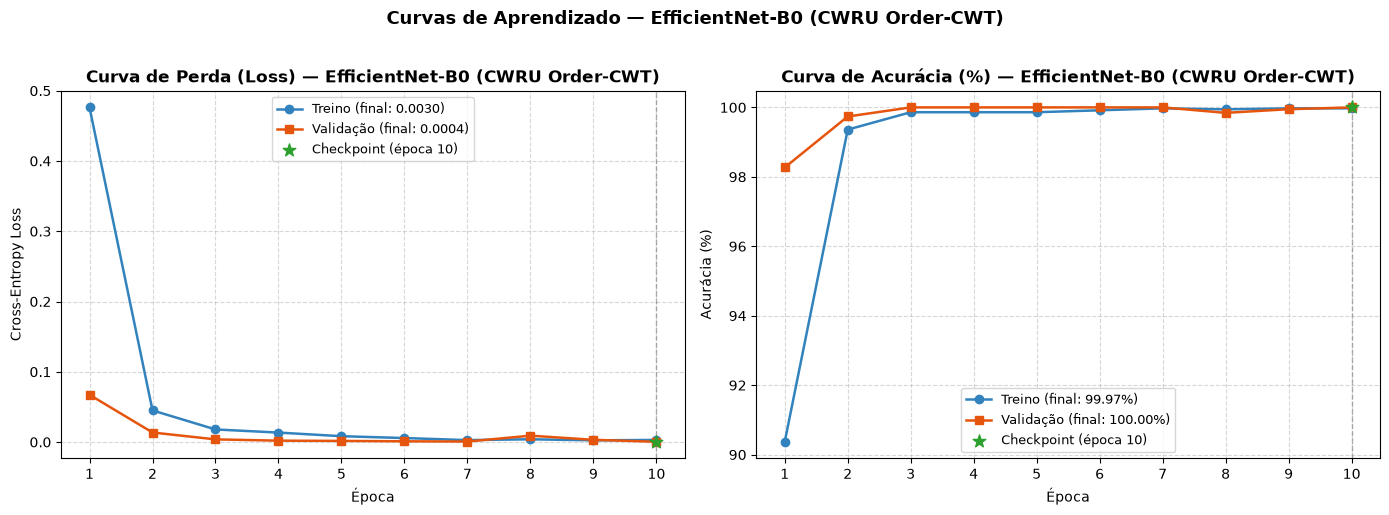

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_cwru_efficientnet.png


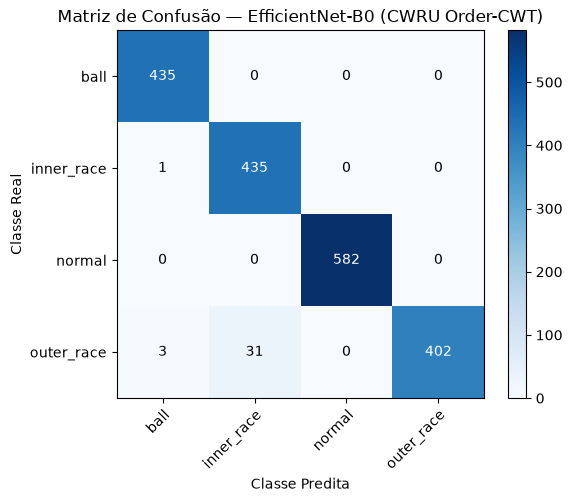

In [5]:
res_cwru_effnet = train_and_evaluate_transfer_model(
    model_name="efficientnet_b0",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_CWRU_DIR,
    checkpoint_prefix="checkpoint_order_cwru"
)
resultados_order["CWRU"]["EfficientNet-B0"] = res_cwru_effnet

plot_training_curves(
    res_cwru_effnet["history"],
    model_name="EfficientNet-B0 (CWRU Order-CWT)",
    save_path="../../docs/images/training_curves_order_cwru_efficientnet.png"
)

plot_confusion_matrix(
    res_cwru_effnet,
    model_name="EfficientNet-B0 (CWRU Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_cwru_efficientnet.png"
)

### 3.4. CWRU Order-CWT: `Inception-v3` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: INCEPTION_V3 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.2933 - Acc: 91.40% | Val Loss: 0.0402 - Acc: 98.43% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.0129 - Acc: 99.92% | Val Loss: 0.0024 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.0149 - Acc: 99.72% | Val Loss: 0.0024 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.0044 - Acc: 100.00% | Val Loss: 0.0019 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0040 - Acc: 99.94% | Val Loss: 0.0010 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.0017 - Acc: 100.00% | Val Loss: 0.0005 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0010 - Acc: 100.00% | Val Loss: 0.0004 - Acc: 100.00% [CHECKPOINT] Modelo ótimo salvo n

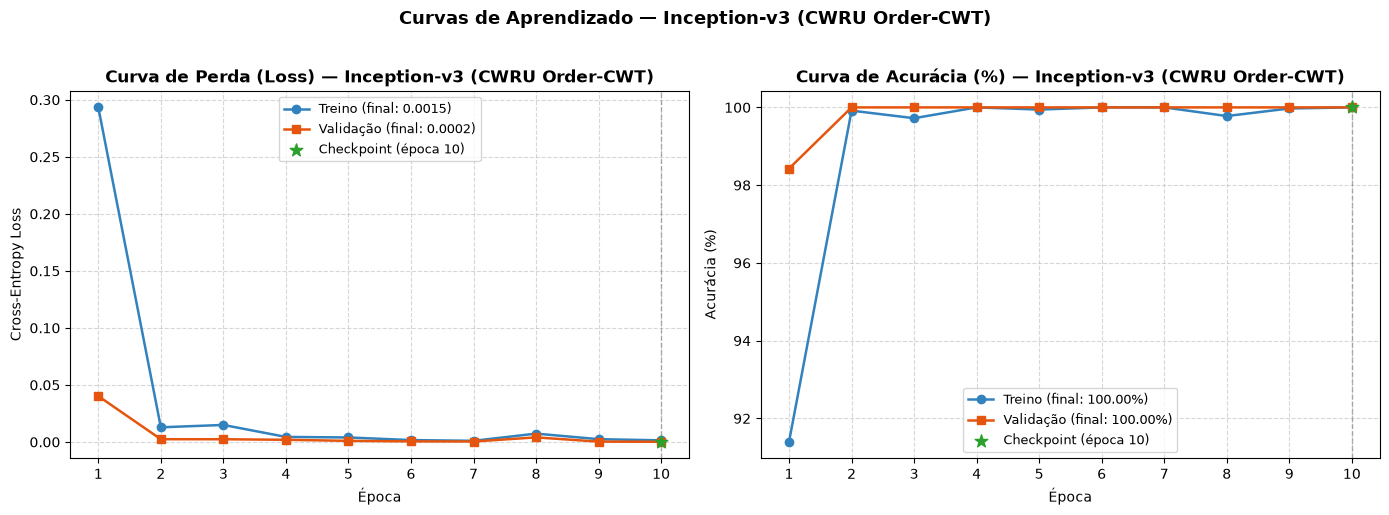

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_cwru_inception.png


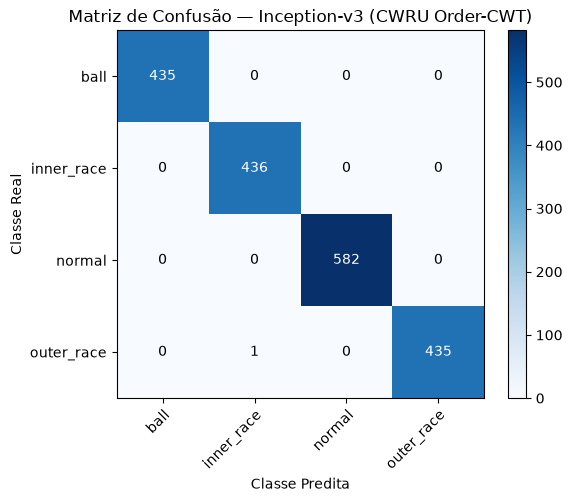

In [6]:
res_cwru_inception = train_and_evaluate_transfer_model(
    model_name="inception_v3",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_CWRU_DIR,
    checkpoint_prefix="checkpoint_order_cwru"
)
resultados_order["CWRU"]["Inception-v3"] = res_cwru_inception

plot_training_curves(
    res_cwru_inception["history"],
    model_name="Inception-v3 (CWRU Order-CWT)",
    save_path="../../docs/images/training_curves_order_cwru_inception.png"
)

plot_confusion_matrix(
    res_cwru_inception,
    model_name="Inception-v3 (CWRU Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_cwru_inception.png"
)

## 4. Treinamento das 4 Arquiteturas no Dataset Paderborn Ângulo-Ordem (`ORDER_PADERBORN_DIR`)

Treinamos as quatro arquiteturas sobre os escalogramas Order-CWT do conjunto da Universidade de Paderborn (3 classes com falhas reais de fadiga sob *Leave-Operating-Condition-Out*).

### 4.1. Paderborn Order-CWT: `BearingCNN` (Rede Autoral)

[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.8259 - Acc: 73.11% | Val Loss: 0.6937 - Acc: 66.67% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.5422 - Acc: 86.47% | Val Loss: 0.8098 - Acc: 66.50% 
Época [03/10] | Treino Loss: 0.3617 - Acc: 96.34% | Val Loss: 0.7694 - Acc: 66.67% 
Época [04/10] | Treino Loss: 0.2433 - Acc: 98.21% | Val Loss: 0.8047 - Acc: 66.33% 
Época [05/10] | Treino Loss: 0.1663 - Acc: 99.23% | Val Loss: 0.7435 - Acc: 66.67% 
Época [06/10] | Treino Loss: 0.1044 - Acc: 99.57% | Val Loss: 0.6188 - Acc: 69.39% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0729 - Acc: 99.74% | Val Loss: 0.5952 - Acc: 70.24% [CHECKPOINT] Modelo ótimo salvo na época 07/10.
Época [08/10] | Treino Loss: 0.0597 - Acc: 99.74% | Val Loss: 0.6312 - Acc: 70.07% 
Época [09/10] | Treino Loss: 0.0440 - Acc: 99.74% | Val Loss: 0.7428 - Acc: 68.20% 
Época [10/10] | Treino Loss: 0.0395 - A

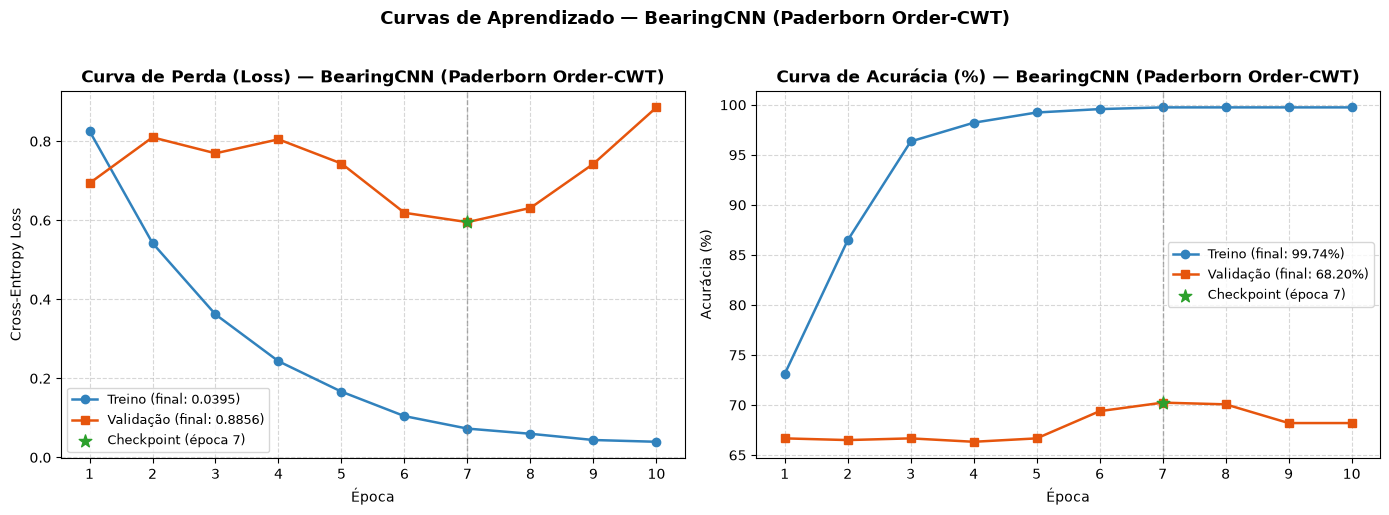

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_paderborn_bearing_cnn.png


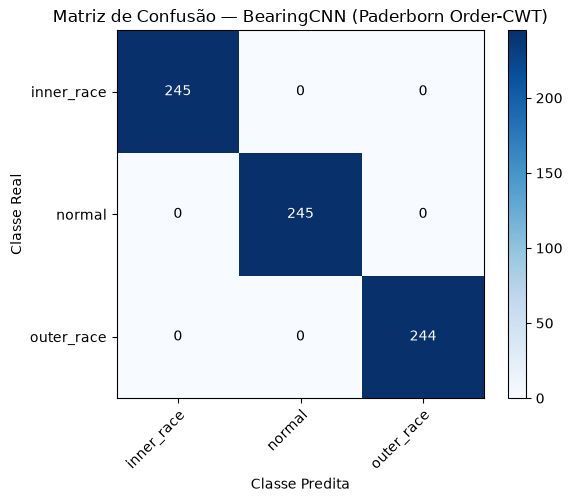

In [7]:
res_pad_bcnn = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_PADERBORN_DIR,
    checkpoint_name="checkpoint_order_paderborn_bearing_cnn_best.pth"
)
resultados_order["Paderborn"]["BearingCNN"] = res_pad_bcnn

plot_training_curves(
    res_pad_bcnn["history"],
    model_name="BearingCNN (Paderborn Order-CWT)",
    save_path="../../docs/images/training_curves_order_paderborn_bearing_cnn.png"
)

plot_confusion_matrix(
    res_pad_bcnn,
    model_name="BearingCNN (Paderborn Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_paderborn_bearing_cnn.png"
)

### 4.2. Paderborn Order-CWT: `ResNet-18` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: RESNET18 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.2149 - Acc: 93.11% | Val Loss: 0.3985 - Acc: 83.16% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.0119 - Acc: 99.91% | Val Loss: 0.3736 - Acc: 84.52% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.0036 - Acc: 100.00% | Val Loss: 0.3966 - Acc: 83.33% 
Época [04/10] | Treino Loss: 0.0050 - Acc: 99.91% | Val Loss: 0.3518 - Acc: 86.22% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0022 - Acc: 100.00% | Val Loss: 0.5065 - Acc: 80.44% 
Época [06/10] | Treino Loss: 0.0013 - Acc: 100.00% | Val Loss: 0.4035 - Acc: 84.18% 
Época [07/10] | Treino Loss: 0.0011 - Acc: 100.00% | Val Loss: 0.4867 - Acc: 81.63% 
Época [08/10] | Treino Loss: 0.0018 - Acc: 100.00% | Val Loss: 0.4722 - Acc: 81.80% 
Época [09/10] | Treino Loss: 0.0014 - Acc: 100.00% | Val Loss: 0.4905 - Acc: 82.14% 
Época [10/10

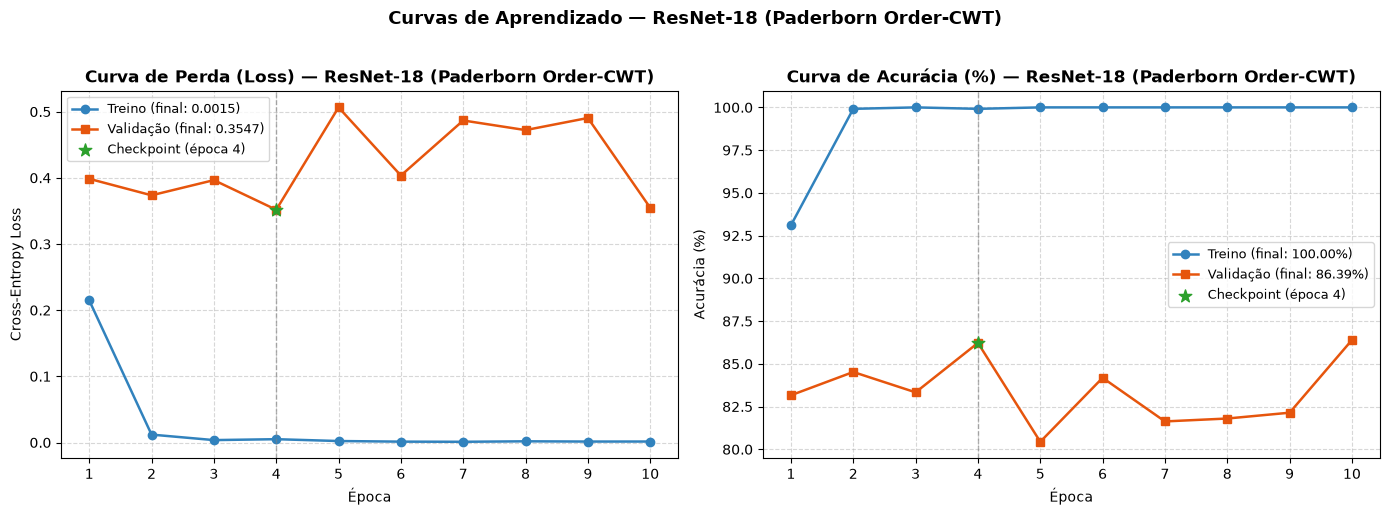

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_paderborn_resnet.png


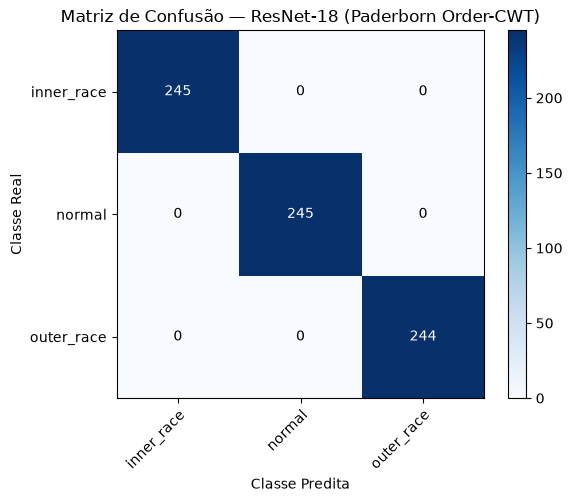

In [8]:
res_pad_resnet = train_and_evaluate_transfer_model(
    model_name="resnet18",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_PADERBORN_DIR,
    checkpoint_prefix="checkpoint_order_paderborn"
)
resultados_order["Paderborn"]["ResNet-18"] = res_pad_resnet

plot_training_curves(
    res_pad_resnet["history"],
    model_name="ResNet-18 (Paderborn Order-CWT)",
    save_path="../../docs/images/training_curves_order_paderborn_resnet.png"
)

plot_confusion_matrix(
    res_pad_resnet,
    model_name="ResNet-18 (Paderborn Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_paderborn_resnet.png"
)

### 4.3. Paderborn Order-CWT: `EfficientNet-B0` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: EFFICIENTNET_B0 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.7813 - Acc: 77.28% | Val Loss: 0.6127 - Acc: 68.71% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.3141 - Acc: 96.51% | Val Loss: 0.6479 - Acc: 69.39% 
Época [03/10] | Treino Loss: 0.0962 - Acc: 99.32% | Val Loss: 0.6151 - Acc: 73.81% 
Época [04/10] | Treino Loss: 0.0572 - Acc: 99.23% | Val Loss: 0.5769 - Acc: 76.70% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0283 - Acc: 99.74% | Val Loss: 0.6663 - Acc: 76.53% 
Época [06/10] | Treino Loss: 0.0185 - Acc: 99.83% | Val Loss: 0.6687 - Acc: 77.38% 
Época [07/10] | Treino Loss: 0.0167 - Acc: 99.74% | Val Loss: 0.7345 - Acc: 76.70% 
Época [08/10] | Treino Loss: 0.0145 - Acc: 99.83% | Val Loss: 0.7472 - Acc: 77.04% 
Época [09/10] | Treino Loss: 0.0174 - Acc: 99.66% | Val Loss: 0.6534 - Acc: 78.40% 
Época [10/10] | Treino Loss: 0.0111 - Acc: 99.83% | Val Lo

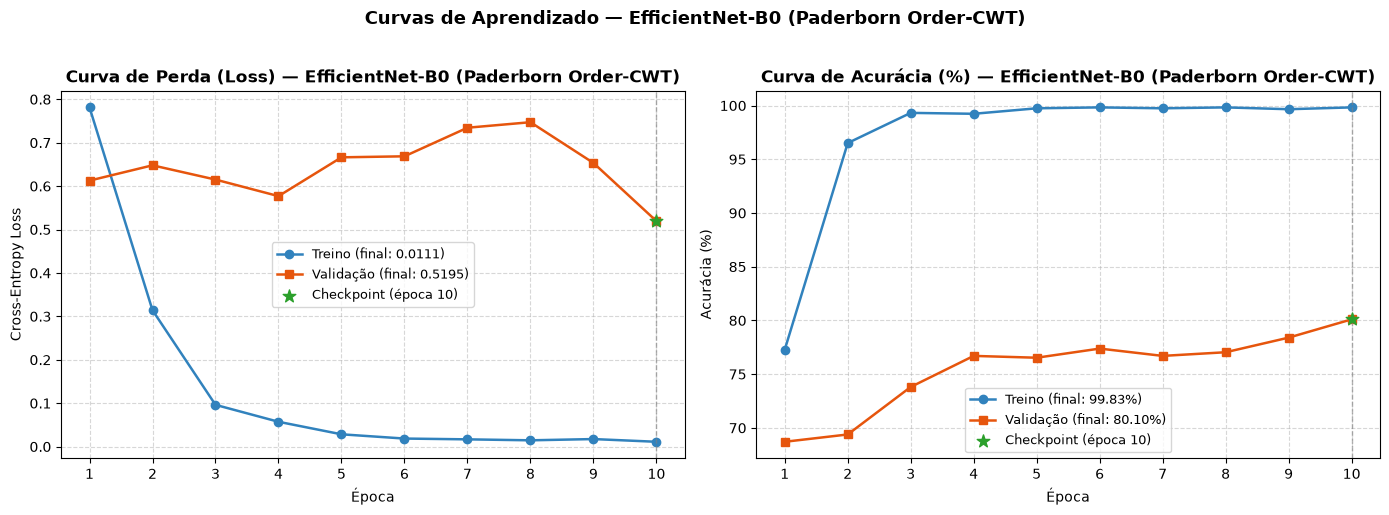

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_paderborn_efficientnet.png


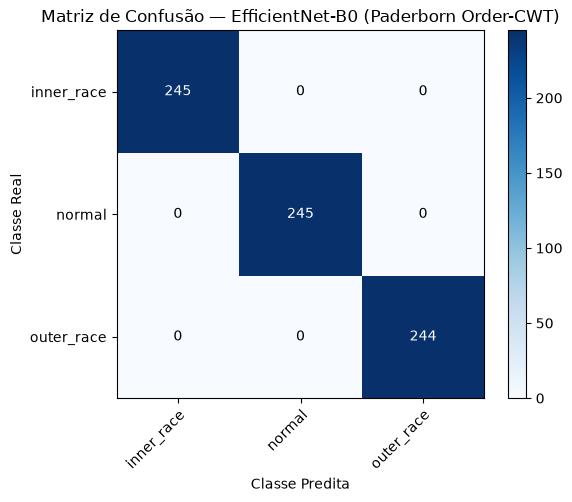

In [9]:
res_pad_effnet = train_and_evaluate_transfer_model(
    model_name="efficientnet_b0",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_PADERBORN_DIR,
    checkpoint_prefix="checkpoint_order_paderborn"
)
resultados_order["Paderborn"]["EfficientNet-B0"] = res_pad_effnet

plot_training_curves(
    res_pad_effnet["history"],
    model_name="EfficientNet-B0 (Paderborn Order-CWT)",
    save_path="../../docs/images/training_curves_order_paderborn_efficientnet.png"
)

plot_confusion_matrix(
    res_pad_effnet,
    model_name="EfficientNet-B0 (Paderborn Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_paderborn_efficientnet.png"
)

### 4.4. Paderborn Order-CWT: `Inception-v3` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: INCEPTION_V3 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.4867 - Acc: 84.43% | Val Loss: 0.4682 - Acc: 75.17% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.0631 - Acc: 98.72% | Val Loss: 0.2402 - Acc: 90.65% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.0137 - Acc: 100.00% | Val Loss: 0.2585 - Acc: 88.44% 
Época [04/10] | Treino Loss: 0.0140 - Acc: 99.83% | Val Loss: 0.2510 - Acc: 89.80% 
Época [05/10] | Treino Loss: 0.0077 - Acc: 99.91% | Val Loss: 0.2385 - Acc: 89.63% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.0036 - Acc: 100.00% | Val Loss: 0.2896 - Acc: 85.54% 
Época [07/10] | Treino Loss: 0.0035 - Acc: 100.00% | Val Loss: 0.2079 - Acc: 90.99% [CHECKPOINT] Modelo ótimo salvo na época 07/10.
Época [08/10] | Treino Loss: 0.0054 - Acc: 99.91% | Val Loss: 0.2243 - Acc: 89.80% 
Época [09/10] | Treino Loss: 0.0034 - Acc: 100.0

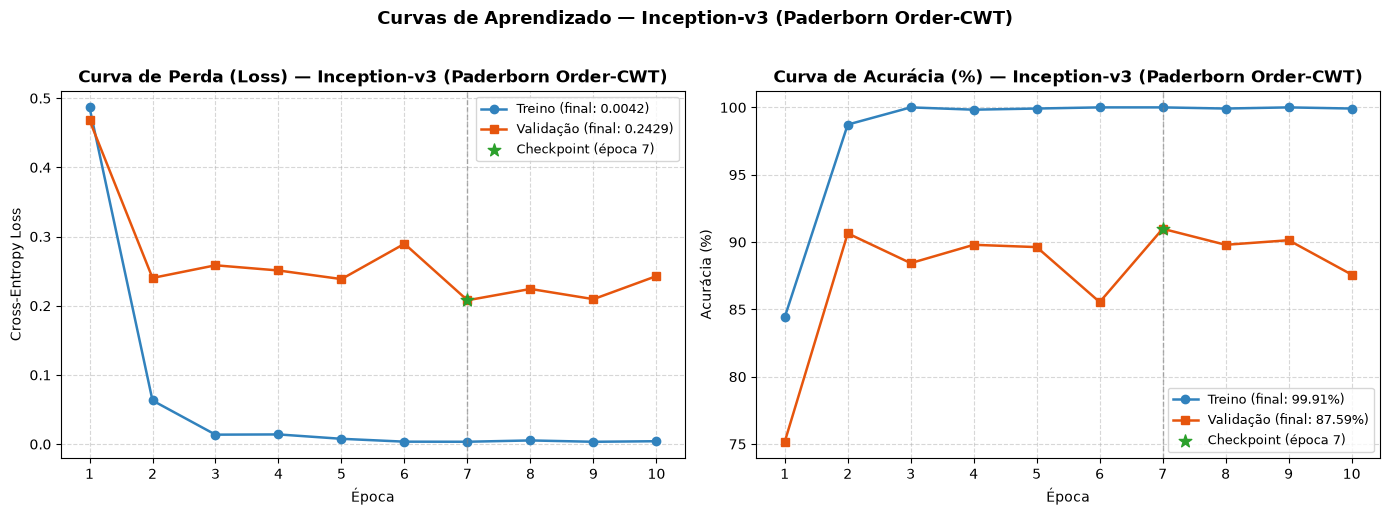

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_paderborn_inception.png


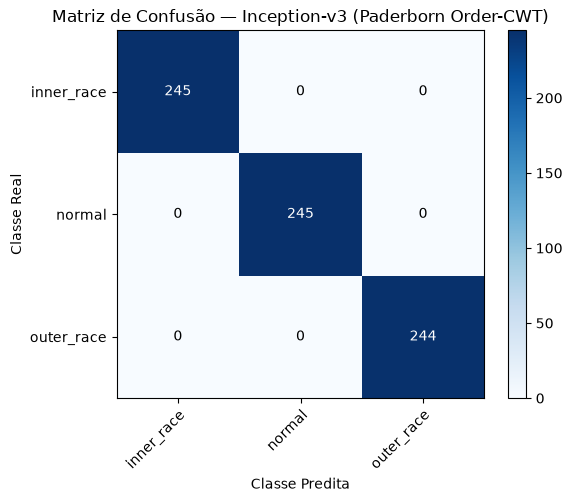

In [10]:
res_pad_inception = train_and_evaluate_transfer_model(
    model_name="inception_v3",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_PADERBORN_DIR,
    checkpoint_prefix="checkpoint_order_paderborn"
)
resultados_order["Paderborn"]["Inception-v3"] = res_pad_inception

plot_training_curves(
    res_pad_inception["history"],
    model_name="Inception-v3 (Paderborn Order-CWT)",
    save_path="../../docs/images/training_curves_order_paderborn_inception.png"
)

plot_confusion_matrix(
    res_pad_inception,
    model_name="Inception-v3 (Paderborn Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_paderborn_inception.png"
)

## 5. Treinamento das 4 Arquiteturas no Dataset XJTU-SY Ângulo-Ordem (`ORDER_XJTU_DIR`)

Treinamos as quatro arquiteturas sobre os escalogramas Order-CWT do conjunto XJTU-SY (3 classes com falhas reais de degradação *run-to-failure* sob *Leave-Bearing-Out*).

### 5.1. XJTU-SY Order-CWT: `BearingCNN` (Rede Autoral)

[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.7741 - Acc: 76.63% | Val Loss: 0.7980 - Acc: 77.14% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.4779 - Acc: 95.19% | Val Loss: 0.5909 - Acc: 74.17% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.2833 - Acc: 98.65% | Val Loss: 0.4559 - Acc: 90.36% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.1590 - Acc: 99.81% | Val Loss: 0.3784 - Acc: 94.88% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0872 - Acc: 100.00% | Val Loss: 0.3303 - Acc: 93.69% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.0548 - Acc: 100.00% | Val Loss: 0.2293 - Acc: 96.90% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0345 - Acc: 100.00% | Val Loss: 0.2283 - Acc: 98.10% [CHECKPOINT] Modelo ótimo salvo na época 07/10.
Época [08/10] | 

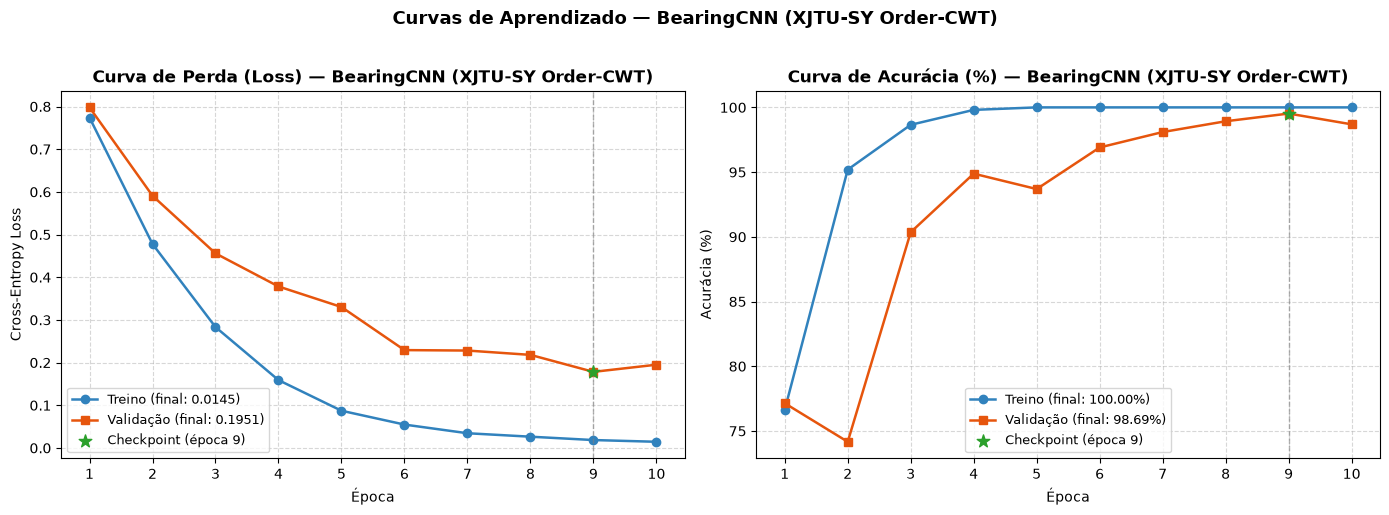

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_xjtu_bearing_cnn.png


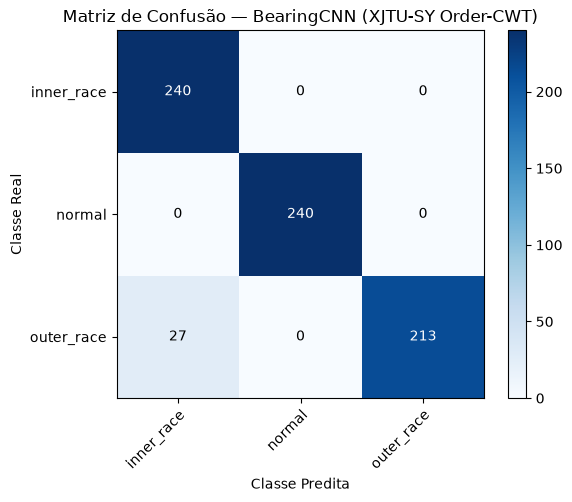

In [11]:
res_xjtu_bcnn = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_XJTU_DIR,
    checkpoint_name="checkpoint_order_xjtu_bearing_cnn_best.pth"
)
resultados_order["XJTU-SY"]["BearingCNN"] = res_xjtu_bcnn

plot_training_curves(
    res_xjtu_bcnn["history"],
    model_name="BearingCNN (XJTU-SY Order-CWT)",
    save_path="../../docs/images/training_curves_order_xjtu_bearing_cnn.png"
)

plot_confusion_matrix(
    res_xjtu_bcnn,
    model_name="BearingCNN (XJTU-SY Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_xjtu_bearing_cnn.png"
)

### 5.2. XJTU-SY Order-CWT: `ResNet-18` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: RESNET18 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.1337 - Acc: 95.58% | Val Loss: 0.3630 - Acc: 81.43% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.0047 - Acc: 100.00% | Val Loss: 0.3287 - Acc: 83.10% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.0016 - Acc: 100.00% | Val Loss: 0.2237 - Acc: 89.64% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.0014 - Acc: 100.00% | Val Loss: 0.2180 - Acc: 90.00% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0010 - Acc: 100.00% | Val Loss: 0.2413 - Acc: 88.33% 
Época [06/10] | Treino Loss: 0.0008 - Acc: 100.00% | Val Loss: 0.1796 - Acc: 91.79% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0007 - Acc: 100.00% | Val Loss: 0.1974 - Acc: 90.60% 
Época [08/10] | Treino Loss: 0.0007 - Acc: 100.00% | Val Loss: 0.2422 - Acc: 87.98% 
É

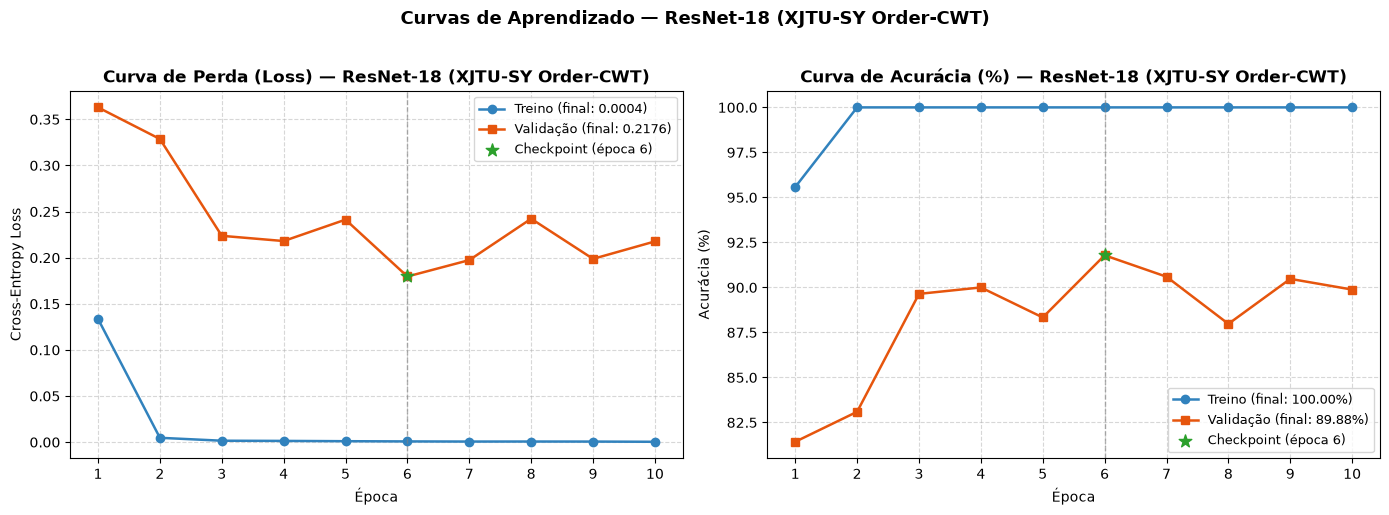

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_xjtu_resnet.png


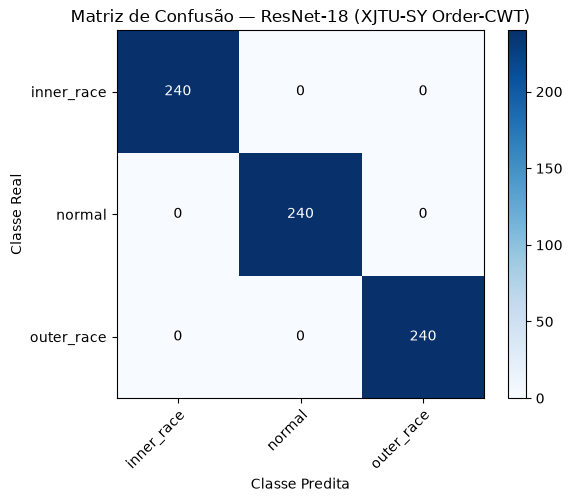

In [12]:
res_xjtu_resnet = train_and_evaluate_transfer_model(
    model_name="resnet18",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_XJTU_DIR,
    checkpoint_prefix="checkpoint_order_xjtu"
)
resultados_order["XJTU-SY"]["ResNet-18"] = res_xjtu_resnet

plot_training_curves(
    res_xjtu_resnet["history"],
    model_name="ResNet-18 (XJTU-SY Order-CWT)",
    save_path="../../docs/images/training_curves_order_xjtu_resnet.png"
)

plot_confusion_matrix(
    res_xjtu_resnet,
    model_name="ResNet-18 (XJTU-SY Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_xjtu_resnet.png"
)

### 5.3. XJTU-SY Order-CWT: `EfficientNet-B0` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: EFFICIENTNET_B0 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.6314 - Acc: 88.37% | Val Loss: 0.6053 - Acc: 73.69% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.1565 - Acc: 99.71% | Val Loss: 0.5304 - Acc: 74.05% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.0482 - Acc: 100.00% | Val Loss: 0.4348 - Acc: 77.02% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.0269 - Acc: 100.00% | Val Loss: 0.4403 - Acc: 77.14% 
Época [05/10] | Treino Loss: 0.0155 - Acc: 100.00% | Val Loss: 0.5274 - Acc: 76.43% 
Época [06/10] | Treino Loss: 0.0112 - Acc: 100.00% | Val Loss: 0.4468 - Acc: 77.98% 
Época [07/10] | Treino Loss: 0.0076 - Acc: 100.00% | Val Loss: 0.4783 - Acc: 77.98% 
Época [08/10] | Treino Loss: 0.0075 - Acc: 100.00% | Val Loss: 0.6151 - Acc: 76.55% 
Época [09/10] | Treino Loss: 0.0064 - Acc: 100.00% | Val Loss: 0.5841 - Acc: 76.79% 
Époc

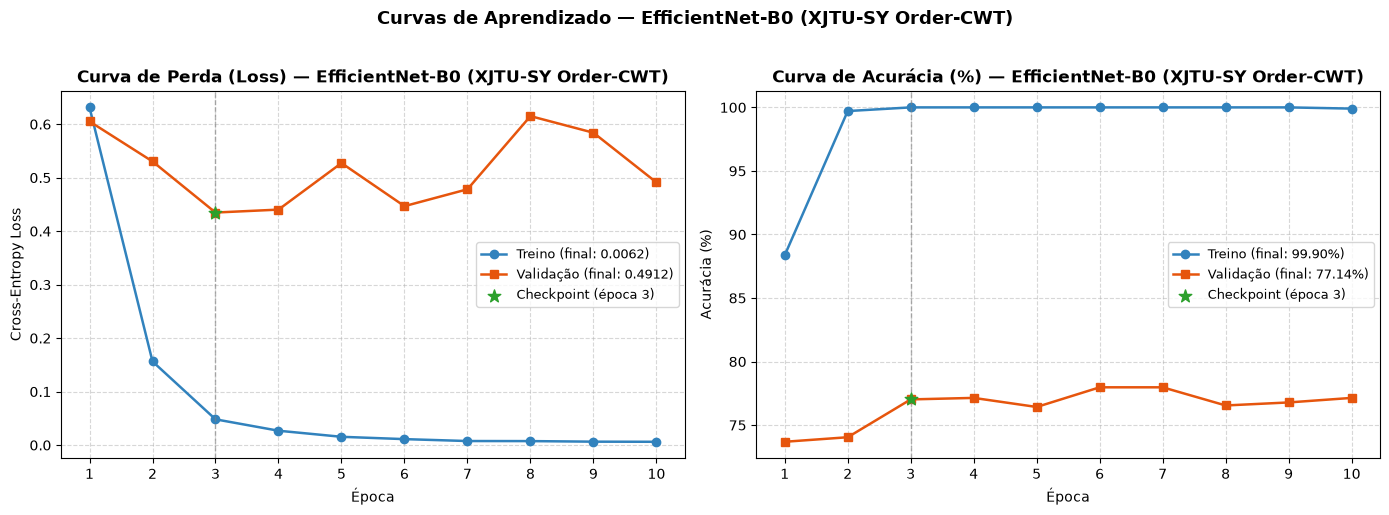

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_xjtu_efficientnet.png


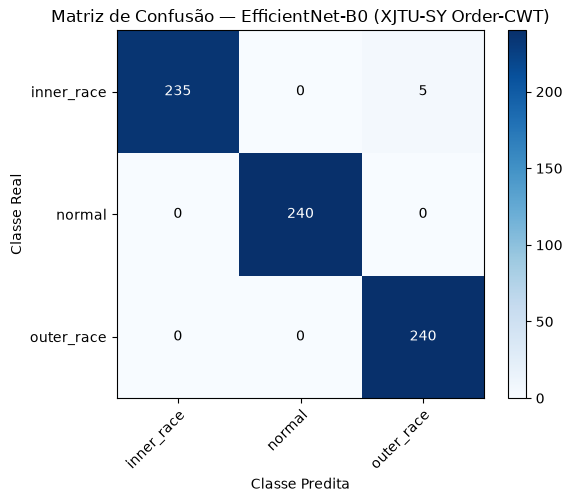

In [13]:
res_xjtu_effnet = train_and_evaluate_transfer_model(
    model_name="efficientnet_b0",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_XJTU_DIR,
    checkpoint_prefix="checkpoint_order_xjtu"
)
resultados_order["XJTU-SY"]["EfficientNet-B0"] = res_xjtu_effnet

plot_training_curves(
    res_xjtu_effnet["history"],
    model_name="EfficientNet-B0 (XJTU-SY Order-CWT)",
    save_path="../../docs/images/training_curves_order_xjtu_efficientnet.png"
)

plot_confusion_matrix(
    res_xjtu_effnet,
    model_name="EfficientNet-B0 (XJTU-SY Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_xjtu_efficientnet.png"
)

### 5.4. XJTU-SY Order-CWT: `Inception-v3` (Fine-Tuning)

[INFO] EXPERIMENTO TRANSFER LEARNING: INCEPTION_V3 | Freeze=False | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.3502 - Acc: 91.06% | Val Loss: 0.6045 - Acc: 68.93% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.0232 - Acc: 99.90% | Val Loss: 0.6867 - Acc: 68.33% 
Época [03/10] | Treino Loss: 0.0077 - Acc: 100.00% | Val Loss: 0.4582 - Acc: 73.45% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.0057 - Acc: 100.00% | Val Loss: 0.4578 - Acc: 72.86% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0040 - Acc: 100.00% | Val Loss: 0.5842 - Acc: 70.48% 
Época [06/10] | Treino Loss: 0.0027 - Acc: 100.00% | Val Loss: 0.4419 - Acc: 74.05% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0022 - Acc: 100.00% | Val Loss: 0.4821 - Acc: 72.26% 
Época [08/10] | Treino Loss: 0.0023 - Acc: 100.00% | Val Loss: 0.6472 - Acc: 69.88% 
Época [09/10] | Treino Loss: 0.0021 - Acc: 10

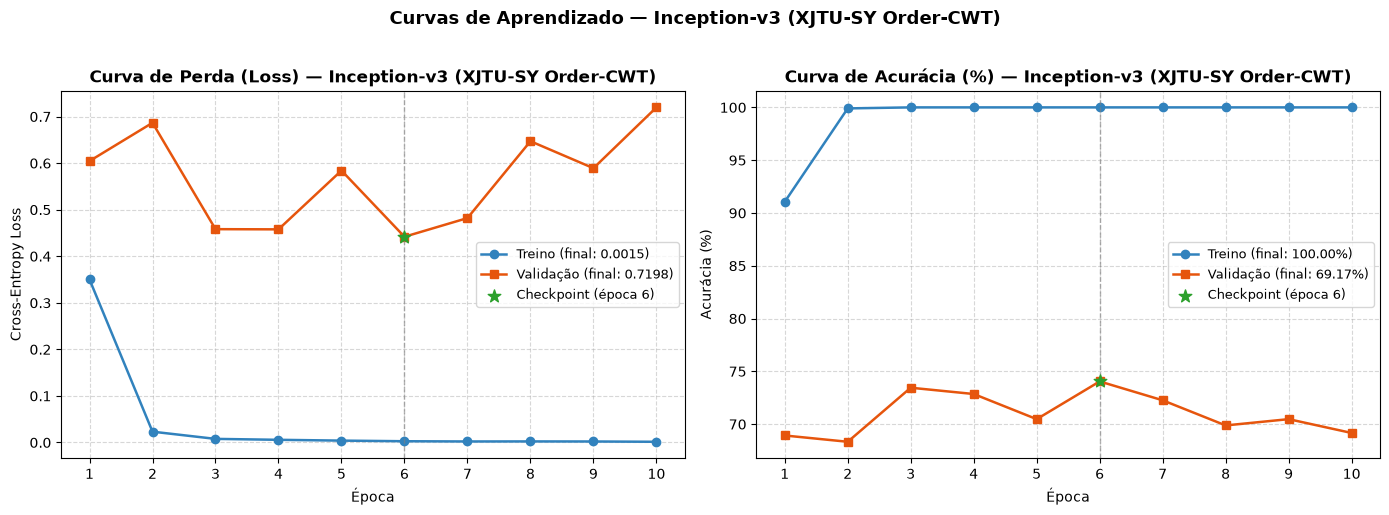

[INFO] Figura salva em: ../../docs/images/confusion_matrix_order_xjtu_inception.png


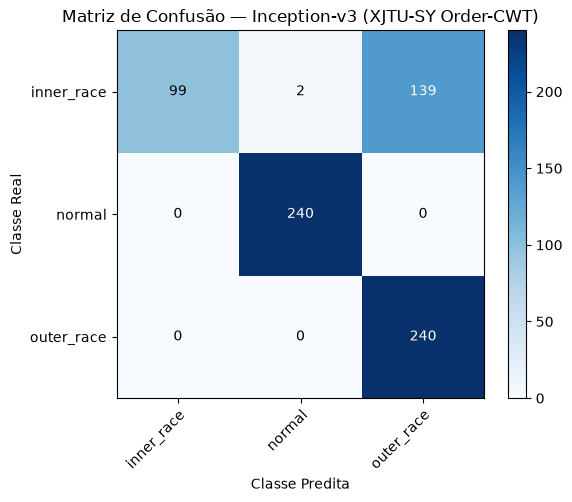

In [14]:
res_xjtu_inception = train_and_evaluate_transfer_model(
    model_name="inception_v3",
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    freeze=False,
    data_dir=ORDER_XJTU_DIR,
    checkpoint_prefix="checkpoint_order_xjtu"
)
resultados_order["XJTU-SY"]["Inception-v3"] = res_xjtu_inception

plot_training_curves(
    res_xjtu_inception["history"],
    model_name="Inception-v3 (XJTU-SY Order-CWT)",
    save_path="../../docs/images/training_curves_order_xjtu_inception.png"
)

plot_confusion_matrix(
    res_xjtu_inception,
    model_name="Inception-v3 (XJTU-SY Order-CWT)",
    save_path="../../docs/images/confusion_matrix_order_xjtu_inception.png"
)

## 6. Resumo Comparativo Intra-Domínio (*In-Domain*) no Domínio Ângulo-Ordem (Order-CWT)

Consolidamos abaixo a acurácia de teste *In-Domain* das **4 arquiteturas** nos três bancos de dados utilizando Order-CWT e salvamos o resumo em `in_domain_order_summary.json`.

In [ ]:
from src.cnn_processor import BearingCNN
from src.transfer_learning import build_transfer_model, get_transfer_dataloaders

datasets_map = {
    "CWRU": (ORDER_CWRU_DIR, "cwru", 4),
    "Paderborn": (ORDER_PADERBORN_DIR, "paderborn", 3),
    "XJTU-SY": (ORDER_XJTU_DIR, "xjtu", 3)
}
models_map = [
    ("BearingCNN", "bearing_cnn", 224),
    ("ResNet-18", "resnet18", 224),
    ("EfficientNet-B0", "efficientnet_b0", 224),
    ("Inception-v3", "inception_v3", 299)
]

summary_in_domain = {ds: {} for ds in datasets_map}
rows = []

for ds_name, (ds_dir, ds_slug, num_c) in datasets_map.items():
    row = {"Conjunto de Dados (Order-CWT)": ds_name}
    for m_label, m_slug, img_sz in models_map:
        if m_label in resultados_order.get(ds_name, {}):
            acc = float(resultados_order[ds_name][m_label]["test_acc"])
        else:
            ckpt = Path(f"checkpoint_order_{ds_slug}_{m_slug}_best.pth")
            if ckpt.exists():
                _, _, te_loader, _ = get_transfer_dataloaders(img_size=img_sz, data_dir=ds_dir)
                if m_label == "BearingCNN":
                    model = BearingCNN(num_classes=num_c).to(device)
                else:
                    model, _ = build_transfer_model(m_slug, num_classes=num_c, freeze_backbone=False)
                    model = model.to(device)
                model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=True))
                model.eval()
                correct, total = 0, 0
                with torch.no_grad():
                    for imgs, labels in te_loader:
                        imgs, labels = imgs.to(device), labels.to(device)
                        preds = model(imgs).argmax(dim=1)
                        correct += (preds == labels).sum().item()
                        total += labels.size(0)
                acc = 100.0 * correct / total
            else:
                acc = float("nan")
        summary_in_domain[ds_name][m_label] = acc
        row[m_label] = f"{acc:.2f}%" if not np.isnan(acc) else "N/A"
    rows.append(row)

df_in_domain_order = pd.DataFrame(rows)
print("=" * 85)
print(" TABELA CONSOLIDADA IN-DOMAIN NO DOMÍNIO ÂNGULO-ORDEM (ORDER-CWT) - 4 ARQUITETURAS")
print("=" * 85)
display(df_in_domain_order)

with open("in_domain_order_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_in_domain, f, indent=2)
print("[INFO] Resumo salvo em: in_domain_order_summary.json")

 TABELA CONSOLIDADA IN-DOMAIN NO DOMÍNIO ÂNGULO-ORDEM (ORDER-CWT) - 4 ARQUITETURAS


,Conjunto de Dados (Order-CWT),BearingCNN,ResNet-18,EfficientNet-B0,Inception-v3
0,CWRU,98.25%,100.00%,98.15%,99.95%
1,Paderborn,100.00%,100.00%,100.00%,100.00%
2,XJTU-SY,96.25%,100.00%,99.31%,80.42%


[INFO] Resumo salvo em: in_domain_order_summary.json


: 